In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")


## Data

`n_samples` is per optimizer. The plots below therefore work from the summary table for the full search, and show fold-level detail only for the top configurations.

In [2]:
folds = pd.read_csv("../out/gridsearch/folds.csv")
results = pd.read_csv("../out/gridsearch/results.csv")

optimizer_order = sorted(results["optimizer"].unique())
palette = dict(zip(optimizer_order, sns.color_palette("colorblind", len(optimizer_order))))

summary_by_optimizer = (
    results.groupby("optimizer")
    .agg(
        n_configs=("config_id", "size"),
        mean_accuracy=("mean_val_accuracy", "mean"),
        best_accuracy=("mean_val_accuracy", "max"),
        median_fold_time_s=("mean_total_time_s", "median"),
    )
    .reindex(optimizer_order)
)

print(f"{len(results):,} configurations, {len(folds):,} fold rows")
summary_by_optimizer.round(4)


245 configurations, 1,225 fold rows


,n_configs,mean_accuracy,best_accuracy,median_fold_time_s
optimizer,,,,
adam,90,0.5203,0.8578,49.6555
muon,78,0.5457,0.8765,45.4191
sgd,77,0.5746,0.8486,43.8281


## Search overview

The first panel is deliberately limited to the strongest configurations; the remaining panels retain every configuration.

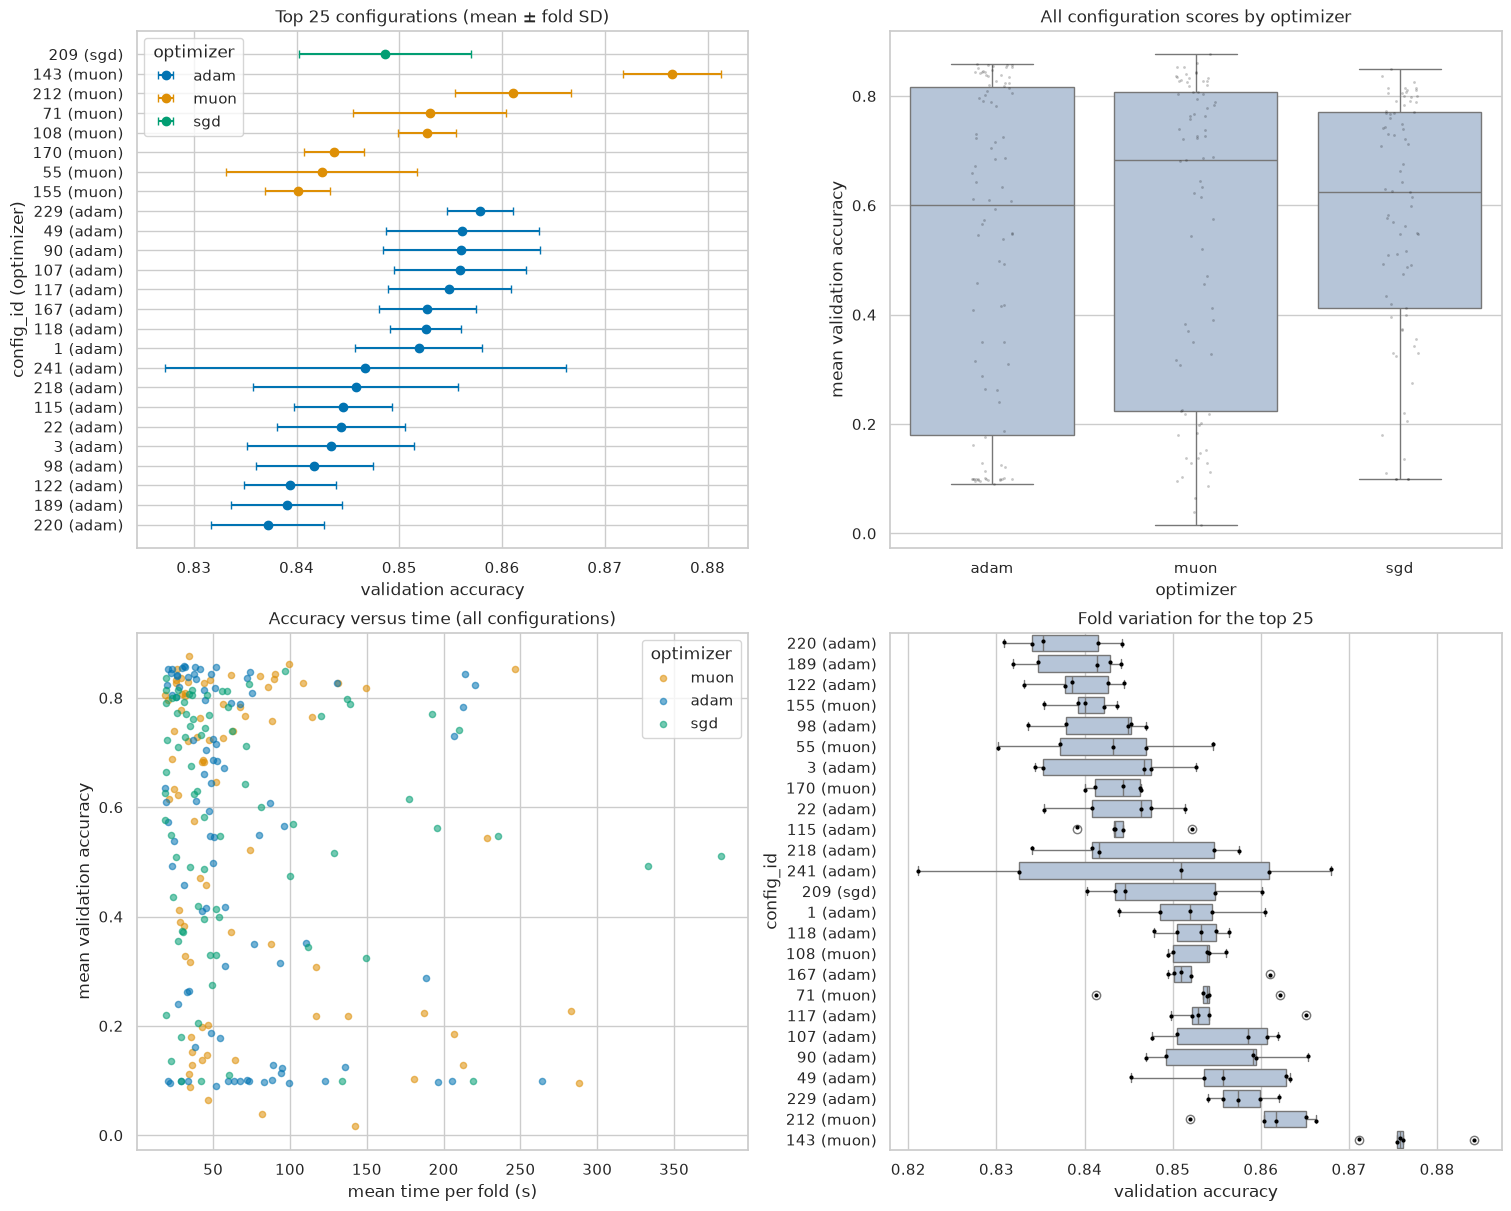

In [3]:
top_n = min(25, len(results))
top = results.nlargest(top_n, "mean_val_accuracy").sort_values("mean_val_accuracy")
top = top.assign(label=top.apply(lambda row: f"{row.config_id} ({row.optimizer})", axis=1))

fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)

for optimizer, group in top.groupby("optimizer", sort=False):
    axes[0, 0].errorbar(
        group["mean_val_accuracy"], group["label"], xerr=group["std_val_accuracy"],
        fmt="o", capsize=3, color=palette[optimizer], label=optimizer,
    )
axes[0, 0].set(title=f"Top {top_n} configurations (mean ± fold SD)", xlabel="validation accuracy", ylabel="config_id (optimizer)")
axes[0, 0].legend(title="optimizer")

sns.boxplot(data=results, x="optimizer", y="mean_val_accuracy", order=optimizer_order, color="lightsteelblue", ax=axes[0, 1])
sns.stripplot(data=results, x="optimizer", y="mean_val_accuracy", order=optimizer_order, color="black", alpha=0.22, size=2, ax=axes[0, 1])
axes[0, 1].set(title="All configuration scores by optimizer", xlabel="optimizer", ylabel="mean validation accuracy")

for optimizer, group in results.groupby("optimizer", sort=False):
    axes[1, 0].scatter(group["mean_total_time_s"], group["mean_val_accuracy"], s=20, alpha=0.55, color=palette[optimizer], label=optimizer)
axes[1, 0].set(title="Accuracy versus time (all configurations)", xlabel="mean time per fold (s)", ylabel="mean validation accuracy")
axes[1, 0].legend(title="optimizer")

top_folds = folds[folds["config_id"].isin(top["config_id"])].copy()
labels_by_config = top.set_index("config_id")["label"]
top_folds["label"] = top_folds["config_id"].map(labels_by_config)
fold_order = top["label"].tolist()
sns.boxplot(data=top_folds, y="label", x="val_accuracy", order=fold_order, color="lightsteelblue", ax=axes[1, 1])
sns.stripplot(data=top_folds, y="label", x="val_accuracy", order=fold_order, color="black", size=3, ax=axes[1, 1])
axes[1, 1].set(title=f"Fold variation for the top {top_n}", xlabel="validation accuracy", ylabel="config_id")

plt.show()


## Hyperparameters versus accuracy

Each point is one cross-validated configuration. Colour makes it possible to see whether a parameter range behaves differently for an optimizer.

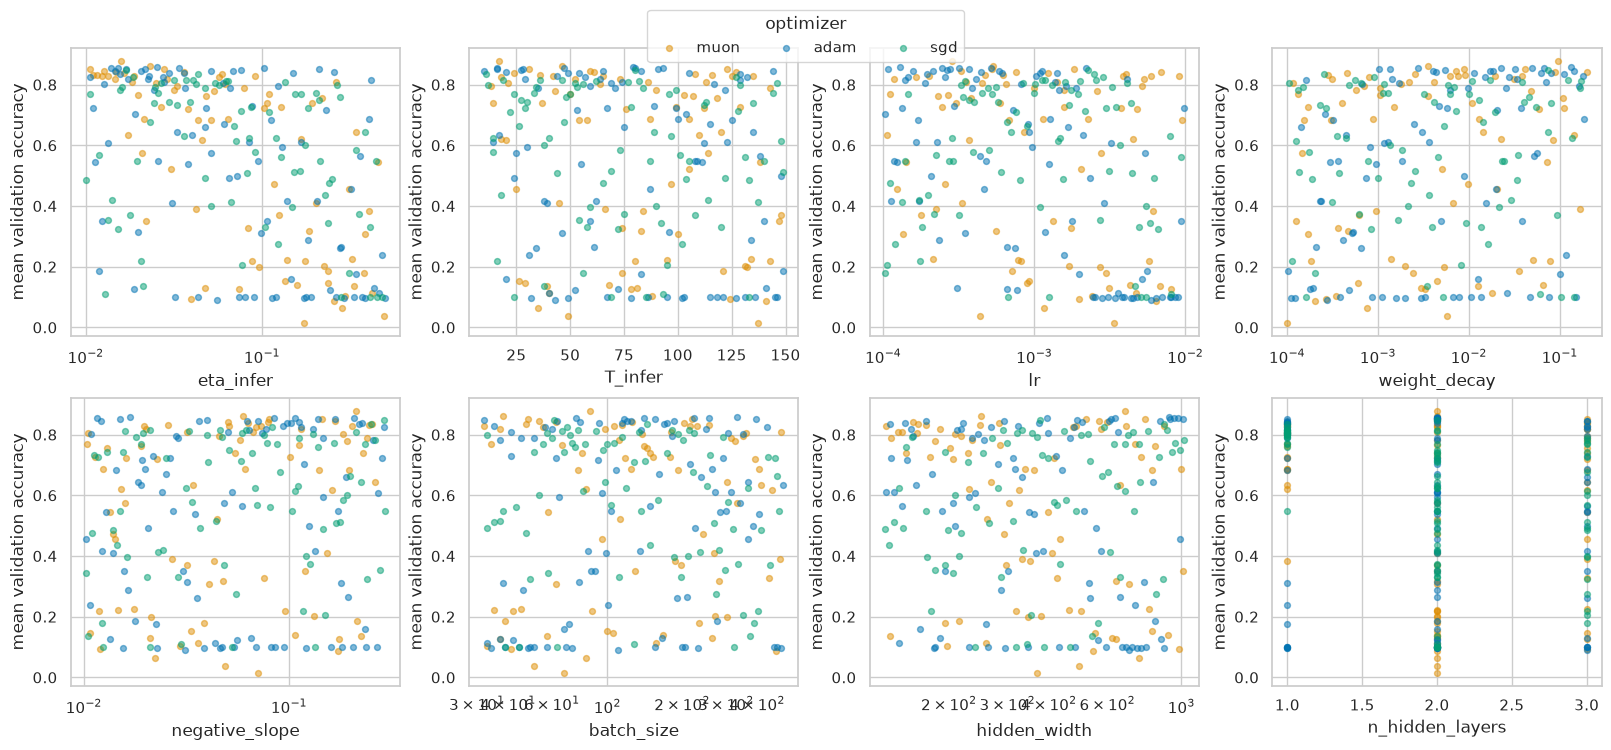

In [4]:
params = [
    "eta_infer", "T_infer", "lr", "weight_decay",
    "negative_slope", "batch_size", "hidden_width", "n_hidden_layers",
]
log_params = {"eta_infer", "lr", "weight_decay", "negative_slope", "batch_size", "hidden_width"}

fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, param in zip(axes.ravel(), params):
    for optimizer, group in results.groupby("optimizer", sort=False):
        ax.scatter(group[param], group["mean_val_accuracy"], s=18, alpha=0.5, color=palette[optimizer], label=optimizer)
    if param in log_params:
        ax.set_xscale("log")
    ax.set(xlabel=param, ylabel="mean validation accuracy")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="optimizer", loc="upper center", ncol=len(optimizer_order), bbox_to_anchor=(0.5, 1.06))
plt.show()


## Best configurations


In [5]:
columns = [
    "config_id", "optimizer", "dims", "eta_infer", "T_infer", "lr", "weight_decay",
    "negative_slope", "batch_size", "mean_val_accuracy", "std_val_accuracy",
    "mean_val_f1_macro", "mean_total_time_s",
]
results.nlargest(20, "mean_val_accuracy")[columns].round(4)


,config_id,optimizer,dims,eta_infer,T_infer,lr,weight_decay,negative_slope,batch_size,mean_val_accuracy,std_val_accuracy,mean_val_f1_macro,mean_total_time_s
0,143,muon,"(784, 675, 337)",0.0159,17,0.0003,0.0953,0.2113,85,0.8765,0.0047,0.8748,34.0878
1,212,muon,"(784, 250, 125)",0.0232,46,0.0005,0.0036,0.0598,38,0.8611,0.0057,0.8590,99.6500
2,229,adam,"(784, 921, 460)",0.0253,79,0.0001,0.1342,0.0168,330,0.8578,0.0032,0.8553,31.1566
3,49,adam,"(784, 975, 487)",0.0139,93,0.0003,0.0492,0.0117,256,0.8561,0.0074,0.8534,38.3376
4,90,adam,"(784, 954, 477)",0.1023,80,0.0002,0.0227,0.1070,140,0.8560,0.0077,0.8530,51.5398
5,107,adam,"(784, 393, 196)",0.0154,16,0.0005,0.0027,0.0849,75,0.8559,0.0064,0.8534,31.8937
6,117,adam,"(784, 630, 315)",0.0339,47,0.0022,0.0676,0.2065,222,0.8548,0.0060,0.8519,29.6408
7,71,muon,"(784, 777, 388, 194)",0.0106,123,0.0018,0.0417,0.1454,48,0.8530,0.0075,0.8504,246.2806
8,167,adam,"(784, 614, 307)",0.0216,16,0.0004,0.0010,0.1681,156,0.8527,0.0047,0.8502,23.5254
9,108,muon,"(784, 516, 258)",0.0278,31,0.0005,0.0088,0.0803,218,0.8527,0.0028,0.8502,26.3073
